In [27]:
import orjson as json
from pathlib import Path
import seaborn as sns
from collections import Counter
from tqdm.cli import tqdm

In [2]:
from sys import path as sys_path
project_root = Path.cwd().parent.parent
if project_root not in sys_path:
    sys_path.append(str(project_root))
data_dir = project_root/"data/"
outputs_dir = project_root/"outputs/"

In [28]:
zero_year_page_n_counter = Counter()
zero_year_book_part_counter = Counter()

 ## Process JSONL files

In [30]:
migration_data_directory = Path(outputs_dir / "json/migration_jsonls/2-final")
files = list(migration_data_directory.glob("*_migration_events.jsonl"))

for file in tqdm(files):
    with open(file, "rb") as f:
        for line in f:
            record = json.loads(line)
            year = record["year_prediction"]
            page_n = record["page_n"]

            if year == 0:
                zero_year_page_n_counter[page_n] += 1

                zero_year_book_part_counter[
                    # roughly book progress as percent
                    int(100 * (page_n / record["image_range_end"]))
                ] += 1

100%|██████████| 468/468 [00:18<00:00, 25.04it/s]


In [31]:
zero_year_page_n_counter_as_list = []
for page, count in zero_year_page_n_counter.items():
    zero_year_page_n_counter_as_list.extend([page] * count)

zero_year_book_part_counter_as_list = []
for part, count in zero_year_book_part_counter.items():
    zero_year_book_part_counter_as_list.extend([part] * count)

Text(0.5, 0, 'Progress (%)')

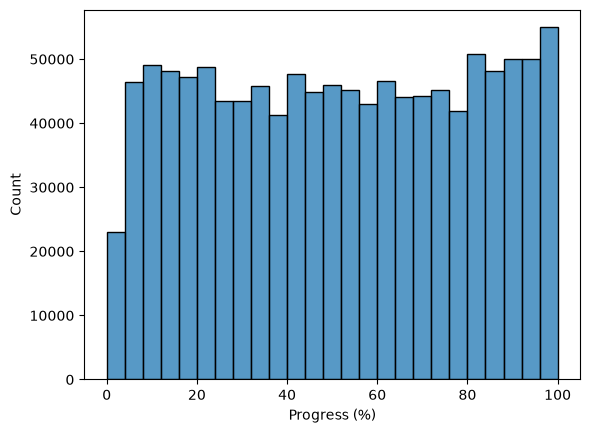

In [32]:
sns.histplot(
    zero_year_book_part_counter_as_list, bins=25
).set_xlabel("Progress (%)")

## Inspecting random books with zero years

In [34]:
{"book": "aanekoski_muuttaneet_1907-1920_ap_sis", "year_range": "1907-1920", "page": "2", "side": "right", "corrected": "1907", "original": "1907"}

{'book': 'aanekoski_muuttaneet_1907-1920_ap_sis',
 'year_range': '1907-1920',
 'page': '2',
 'side': 'right',
 'corrected': '1907',
 'original': '1907'}

In [35]:
year_prediction_dir = data_dir/"year-predictions"

In [58]:
year_predictions_files = year_prediction_dir.glob("*.jsonl")
all_year_objects = []
for file in year_predictions_files:
    with open(file, "rb") as fp:
        all_year_objects.extend(json.loads(line) for line in fp)

In [63]:
import pandas as pd


all_year_data = pd.DataFrame.from_dict(
    all_year_objects
)

In [ ]:
for b, g in all_year_data.groupby("book"):

,book,year_range,page,side,corrected,original
314589,aanekoski_muuttaneet_1907-1920_ap_sis,1907-1920,2,left,1907,???
314590,aanekoski_muuttaneet_1907-1920_ap_sis,1907-1920,2,right,1907,1907
314591,aanekoski_muuttaneet_1907-1920_ap_sis,1907-1920,3,left,1907,1907.
314592,aanekoski_muuttaneet_1907-1920_ap_sis,1907-1920,3,right,1908,1908
314593,aanekoski_muuttaneet_1907-1920_ap_sis,1907-1920,4,left,1908,1908.
314594,aanekoski_muuttaneet_1907-1920_ap_sis,1907-1920,4,right,1908,1908
314595,aanekoski_muuttaneet_1907-1920_ap_sis,1907-1920,5,left,1908,1908.
314596,aanekoski_muuttaneet_1907-1920_ap_sis,1907-1920,5,right,1909,1909.
314597,aanekoski_muuttaneet_1907-1920_ap_sis,1907-1920,6,left,1909,1909
314598,aanekoski_muuttaneet_1907-1920_ap_sis,1907-1920,6,right,1910,1910.
